<a href="https://colab.research.google.com/github/Mashael-fs/IT326-Cardiovascular-Disease/blob/main/Final_Report.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Cardiovascular Disease Predicion Analyaia**

### Importing Libraries

In [ ]:
import pandas as pd

# Import all necessary libraries for Phase 1,2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tabulate import tabulate
from sklearn.preprocessing import StandardScaler

# Import all necessary libraries for Phase 3
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from tabulate import tabulate
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.cm as cm
from sklearn.metrics import silhouette_score, silhouette_samples



sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)


# **Phase 1**

###Project Goal:

The primary goal of this project is to analyze cardiovascular health data using classification and clustering techniques. The classification task aims to classify patients based on the presence or absence of cardiovascular disease using their health and lifestyle characteristics. In addition, clustering techniques will be used to group patients with similar characteristics and identify meaningful patterns within the dataset. By applying these data mining techniques, the project aims to better understand the factors and patterns associated with cardiovascular disease.

## **[1] Problem**

Cardiovascular disease is a major health concern, and identifying patterns associated with its presence can help improve the understanding of patient risk factors. This project aims to analyze cardiovascular health data and determine whether a patient is likely to have cardiovascular disease based on health and lifestyle-related attributes such as age, blood pressure, cholesterol level, glucose level, weight, smoking status, alcohol consumption, and physical activity.

The problem will be addressed using data mining techniques. Classification will be used to predict the presence or absence of cardiovascular disease through the target attribute cardio, while clustering will be used to group patients with similar characteristics and reveal patterns within the dataset.

This problem is important because cardiovascular disease is influenced by several measurable health and lifestyle factors. Analyzing these factors using classification and clustering techniques can help identify meaningful relationships in the data and provide a better understanding of the characteristics associated with cardiovascular disease.

## **[2] Data Mining Task**

This study will apply two main data mining strategies: classification and clustering, to assess the risk of cardiovascular disease. The classification technique will involve training a model to predict whether a patient is at risk of cardiovascular disease using various health-related and lifestyle features such as blood pressure (⁠ap_hi⁠, ⁠ap_lo⁠), cholesterol levels, weight, height, age, and more. The model will be designed to focus specifically on identifying the presence or absence of cardiovascular disease (⁠cardio⁠). In contrast, clustering will categorize patients into groups based on similar attributes, regardless of whether they have cardiovascular disease or not. This unsupervised method will help us uncover hidden patterns and relationships within the dataset, offering valuable insights into patient profiles.

## **[3] Data**


The dataset used in this project was obtained from Kaggle https://www.kaggle.com/datasets/sulianova/cardiovascular-disease-dataset and contains information about 70,000 patients across 13 attributes. These attributes include age, gender, height, weight, blood pressure, cholesterol, glucose, smoking, alcohol consumption, physical activity, and cardiovascular disease status.

The target variable, cardio, indicates whether a patient has cardiovascular disease. The dataset contains 35,021 patients without cardiovascular disease and 34,979 patients with cardiovascular disease, making the two classes nearly balanced.

The original dataset was analyzed in Phase 1 to understand its attributes, distributions, and data quality. In Phase 2, the data was cleaned by removing outliers and preparing numerical features for analysis.

The dataset is suitable for classification to predict cardiovascular disease and clustering to group patients with similar health characteristics.

In [ ]:

# Dataset Description

# Load the original dataset
df = pd.read_csv("Raw_dataset.csv", sep=";")

# General information
num_attributes = df.shape[1]
num_objects = df.shape[0]
class_name = "cardio"

print("General Information:\n")
print("Number of attributes:", num_attributes)
print("Number of objects:", num_objects)
print("Class label:", class_name)

# Attribute types
print("\nAttribute types:")
print(df.dtypes)

# Dataset preview
print("\nDataset Preview:")
display(df.head())

# Dataset information
print("\nDataset Info:")
df.info()

General Information:

Number of attributes: 13
Number of objects: 70000
Class label: cardio

Attribute types:
id               int64
age              int64
gender           int64
height           int64
weight         float64
ap_hi            int64
ap_lo            int64
cholesterol      int64
gluc             int64
smoke            int64
alco             int64
active           int64
cardio           int64
dtype: object

Dataset Preview:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


Class Distribution:

The target variable `cardio` represents the presence or absence of cardiovascular disease. The dataset contains 35,021 patients without the disease (class 0) and 34,979 patients with the disease (class 1). The two classes are nearly balanced.

In [ ]:

# Class Distribution

print("Target Column: cardio")

count_0 = (df["cardio"] == 0).sum()
count_1 = (df["cardio"] == 1).sum()

print(f"Patients WITHOUT cardiovascular disease (0): {count_0}")
print(f"Patients WITH cardiovascular disease (1): {count_1}")


Target Column: cardio
Patients WITHOUT cardiovascular disease (0): 35021
Patients WITH cardiovascular disease (1): 34979


## [4] Data Preprocessing

To prepare the dataset for effective modeling, several preprocessing steps were executed based on the findings from Phase 2. First, an assessment of the dataset confirmed zero explicit missing values across all 13 attributes, making imputation unnecessary. To eliminate extreme noise and measurement errors, unrealistic outliers in blood pressure (such as negative or excessively high values of ⁠ap_hi⁠ and ⁠ap_lo⁠) along with extreme height and weight outliers were filtered out using standard clinical bounds and Interquartile Range (IQR) analysis. For feature transformation, age was converted from days into full years to improve visual and analytical interpretability. Categorical and indicator variables (such as cholesterol, glucose, gender, smoking status, alcohol intake, and physical activity) were verified as properly encoded numerical values, and an evaluation of the target variable (⁠cardio⁠) confirmed a balanced binary class distribution (~50/50) requiring no rebalancing procedures. Finally, standard z-score normalization (⁠StandardScaler⁠) was applied to continuous features (⁠age⁠, ⁠height⁠, ⁠weight⁠, ⁠ap_hi⁠, and ⁠ap_lo⁠) to bring variables onto a consistent scale, ensuring optimal conditions for both distance-sensitive clustering algorithms and classification models. Overall, these preprocessing techniques significantly improved data quality, reduced noise, and guaranteed dataset integrity for subsequent modeling stages.

# **Phase** **2**:

## Data Analysis

### 1- Statistical Summaries


In [ ]:
df.describe()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


The statistical summary provides an overview of the numerical attributes by showing the count, mean, standard deviation, minimum, quartiles, and maximum values. It also reveals some unusual values, especially in blood pressure, height, and weight, which may indicate noisy data or outliers that require further investigation and preprocessing.

### 2- Missing Values Analysis


In [ ]:
missing = df.isnull().sum()

print("Missing Values:")
print(missing)

print("\nTotal Missing Values: ", missing.sum())

Missing Values:
id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64

Total Missing Values:  0


The missing values analysis shows the number of missing values in each attribute of the dataset. The results indicate that there are no missing values in any of the attributes, so no missing value handling technique is required.

## **Visualizations:**

### 3- Categorical Attribute Distributions - Bar Plots

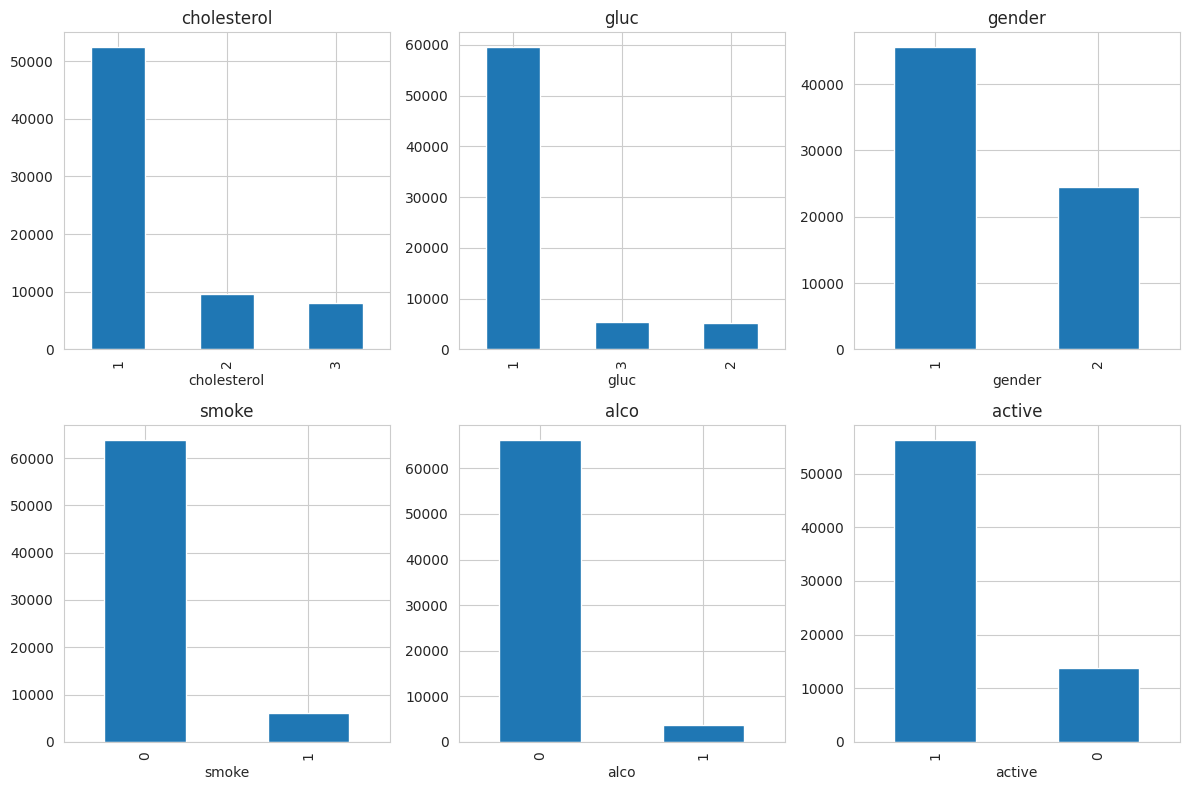

In [ ]:
cat_cols = ["cholesterol", "gluc", "gender", "smoke", "alco", "active"]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()
for i, col in enumerate(cat_cols):
    df[col].value_counts().plot(kind='bar', ax=axes[i])
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

The bar plots show the distribution of categorical variables such as smoking, alcohol use, activity, cholesterol, glucose, and gender. Most values are concentrated in one category, indicating imbalance in some variables. This shows that the data is already numerically encoded, so no major preprocessing is needed. However, class imbalance may need to be handled in later modeling steps

### 4- Numeric attribute distributions - Histograms

Histograms of `age`, `height`, `weight`, `ap_hi` (systolic BP) and `ap_lo` (diastolic BP).

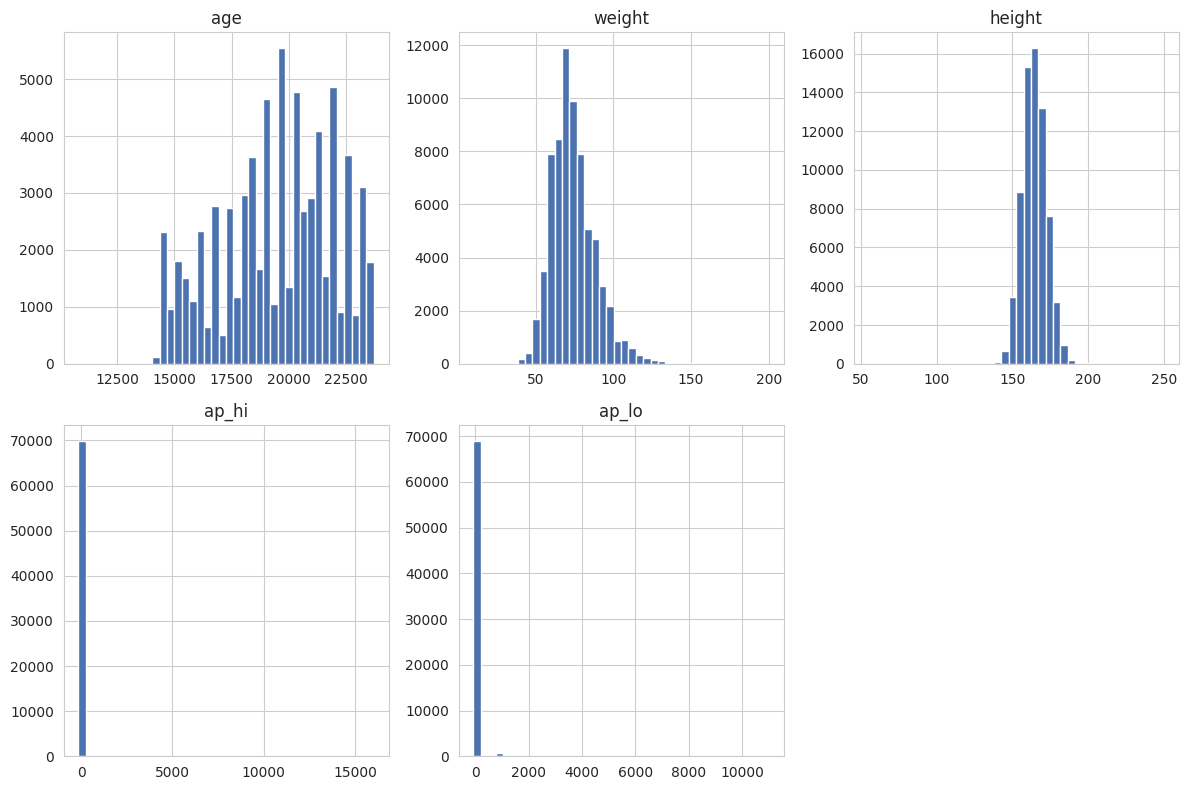

In [ ]:
numeric_cols = ["age", "weight", "height", "ap_hi", "ap_lo"]

df[numeric_cols].hist(bins=40, figsize=(12, 8), layout=(2, 3), color="#4C72B0")
plt.tight_layout()
plt.show()

These histograms illustrate the distributions of the numerical features, where ⁠age⁠ spans a broad range in days, ⁠weight⁠ and ⁠height⁠ show approximately normal distributions, and blood pressure features (⁠ap_hi⁠ and ⁠ap_lo⁠) are heavily compressed due to extreme outliers exceeding 10,000. This guided our preprocessing decisions specifically for these continuous attributes: the presence of unrealistic values indicated the need for noise removal to discard severe outliers, the wide age span justified applying discretisation to group ages into categorical intervals, and the differing numerical scales across the features confirmed the necessity of normalisation to standardize them onto a uniform scale.

###5- Box Plot

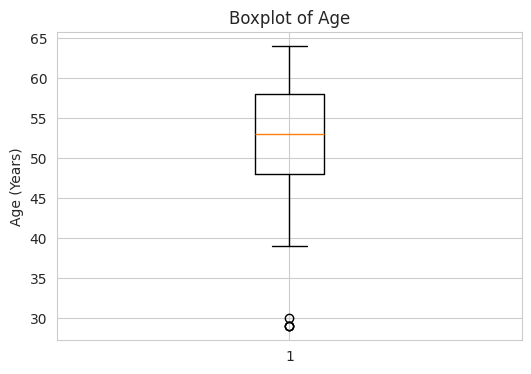

five number summary:
Min: 29
Q1: 48.0
Median: 53.0
Q3: 58.0
Max: 64


In [ ]:
age_in_years=(df["age"]/365).astype(int)
plt.figure(figsize=(6,4))
plt.boxplot(age_in_years)
plt.title("Boxplot of Age")
plt.ylabel("Age (Years)")
plt.show()
q1 = np.percentile(age_in_years, 25)
q2 = np.percentile(age_in_years, 50)
q3 = np.percentile(age_in_years, 75)
print("five number summary:")
print("Min:", np.min(age_in_years))
print("Q1:", q1)
print("Median:", q2)
print("Q3:", q3)
print("Max:", np.max(age_in_years))

Based on the displayed boxplot, the minimum value is 29 and the maximum value is 64. The lower whisker is at 39, and the upper whisker is at 64. The first quartile (Q1) is approximately 48, the third quartile (Q3) is approximately 58, and the median, represented by the orange line, is 53. Two outliers (29 and 30) are shown.


### Outlier







In [ ]:
Q1 = np.percentile(age_in_years, 25)
Q3 = np.percentile(age_in_years, 75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = set(age_in_years[(age_in_years < lower) | (age_in_years > upper)])
print("Outliers:",outliers)

Outliers: {29, 30}


The interquartile range (IQR) method was used to identify outliers in age: values below Q1 − 1.5×IQR or above Q3 + 1.5×IQR are considered outliers. Consequently, two values, 29 and 30, were detected.

### 6- Relationship Between Numeric Attributes - Scatter Plot

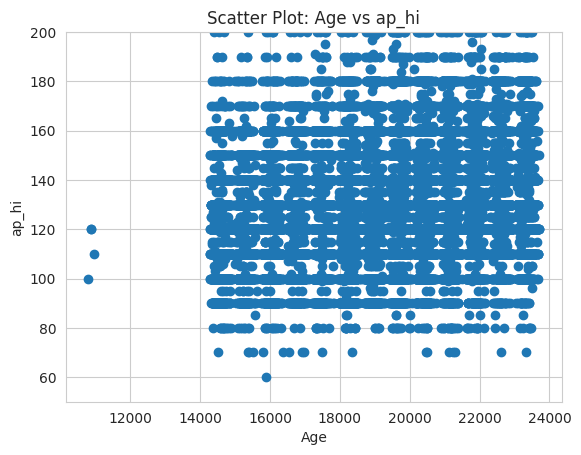

In [ ]:
plt.figure()
plt.scatter(df['age'], df['ap_hi'])
plt.title("Scatter Plot: Age vs ap_hi")
plt.xlabel("Age")
plt.ylabel("ap_hi")
plt.ylim(50, 200)
plt.show()


This scatter plot illustrates the relationship between ⁠Age⁠ (recorded in days) and systolic blood pressure (⁠ap_hi⁠), showing dense horizontal clustering due to rounded clinical measurements along with scattered extreme points. This information guided our preprocessing decisions specifically for these two attributes: the isolated outlying points highlighted the necessity of noise removal to eliminate erroneous measurements and outliers, the continuous, large scale of age values supported applying discretisation to categorize age into meaningful clinical brackets, and the significant discrepancy between the scales of the two axes (thousands vs. tens) confirmed the clear need for normalisation to bring both features onto a standardized, comparable scale.

###7- Class label distribution

`cardio` (0 = no cardiovascular disease, 1 = disease) is the target attribute.

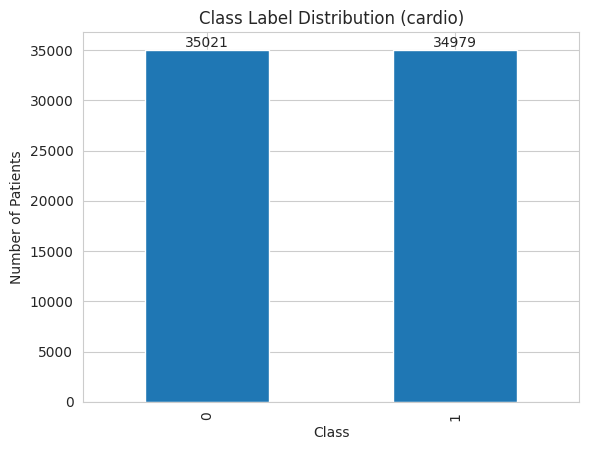

In [ ]:
plt.figure()
ax= df['cardio'].value_counts().plot(kind='bar')
ax.bar_label(ax.containers[0])
plt.title("Class Label Distribution (cardio)")
plt.xlabel("Class")
plt.ylabel("Number of Patients")
plt.show()

This bar plot illustrates the distribution of the target variable ⁠cardio⁠, showing 35,021 patients without cardiovascular disease and 34,979 with cardiovascular disease across 70,000 records, confirming an almost exact 50:50 distribution. This information demonstrates that the target variable is completely balanced, cleanly defined into binary classes, and free from erroneous entries, confirming that it is already in an ideal state and requires no preprocessing whatsoever.

# Data Preprocessing

###Raw Dataset

In [ ]:
print(df.head())
print(df.info())
print(df.describe())

   id    age  gender  height  weight  ap_hi  ap_lo  cholesterol  gluc  smoke  \
0   0  18393       2     168    62.0    110     80            1     1      0   
1   1  20228       1     156    85.0    140     90            3     1      0   
2   2  18857       1     165    64.0    130     70            3     1      0   
3   3  17623       2     169    82.0    150    100            1     1      0   
4   4  17474       1     156    56.0    100     60            1     1      0   

   alco  active  cardio  
0     0       1       0  
1     0       1       1  
2     0       0       1  
3     0       1       1  
4     0       0       0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4

The raw dataset represents the original data before applying the preprocessing techniques.

## **Data preprocessing techniques:**




### 1- Noise Removal

In [ ]:
numeric_cols = ["height", "weight", "ap_hi", "ap_lo"]

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df = df[(df[col] >= lower) & (df[col] <= upper)]

print("Outliers removed. Dataset shape after cleaning:", df.shape)

Outliers removed. Dataset shape after cleaning: (62505, 13)


The Interquartile Range (IQR) method was applied to the continuous numerical features (⁠height⁠, ⁠weight⁠, ⁠ap_hi⁠, and ⁠ap_lo⁠). Upper and lower bounds were defined as Q3 + 1.5 IQR and Q1 - 1.5 IQR respectively, filtering out extreme physiological anomalies such as unrealistic blood pressure values and implausible body measurements.

Successfully eliminated noisy records and severe outliers, cleaning the dataset and reducing the total count from 70,000 to 62,505 valid records.

### 2- Discretization

In [ ]:
df['age_years'] = (df['age'] / 365).astype(int)

df['Age_Group'] = pd.cut(df['age_years'],
                         bins=3,
                         labels=['Young', 'Middle', 'Old'])

print("Age Group Column:")
print(tabulate(df[['age_years', 'Age_Group']].head().reset_index(drop=True),
      headers='keys',
      tablefmt='fancy_grid',
      stralign='center',
      numalign='center'))

Age Group Column:
╒════╤═════════════╤═════════════╕
│    │  age_years  │  Age_Group  │
╞════╪═════════════╪═════════════╡
│ 0  │     50      │   Middle    │
├────┼─────────────┼─────────────┤
│ 1  │     55      │     Old     │
├────┼─────────────┼─────────────┤
│ 2  │     51      │   Middle    │
├────┼─────────────┼─────────────┤
│ 3  │     48      │   Middle    │
├────┼─────────────┼─────────────┤
│ 4  │     60      │     Old     │
╘════╧═════════════╧═════════════╛


The age attribute (originally in days) was converted into years (⁠age_years = age / 365⁠) and then binned using equal-width interval discretization (⁠pd.cut⁠ with ⁠bins=3⁠) into three categorical age brackets: Young, Middle, and Old.

Simplified the age feature into meaningful clinical groups (⁠Age_Group⁠), enhancing feature interpretability and capturing non-linear age-group trends for pattern analysis.

### 3- Z-score Normalization

In [ ]:
continuous_cols = ["age", "height", "weight", "ap_hi", "ap_lo", "age_years"]

scaler = StandardScaler()
df[continuous_cols] = scaler.fit_transform(df[continuous_cols])

print("First 5 rows after Normalization:")
df.head()

First 5 rows after Normalization:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,Age_Group
0,0,-0.447523,2,0.477189,-0.911080,-1.149069,-0.221405,1,1,0,0,1,0,-0.431208,Middle
1,1,0.298797,1,-1.116160,0.963105,0.950343,1.081815,3,1,0,0,1,1,0.310276,Old
2,2,-0.258808,1,0.078852,-0.748108,0.250539,-1.524624,3,1,0,0,0,1,-0.282911,Middle
3,3,-0.760693,2,0.609968,0.718646,1.650146,2.385035,1,1,0,0,1,1,-0.727801,Middle
5,8,0.984517,1,-1.780056,-0.503649,-0.449265,-0.221405,2,2,0,0,0,0,1.051760,Old


Applied ⁠StandardScaler⁠ to all continuous features (⁠age⁠, ⁠height⁠, ⁠weight⁠, ⁠ap_hi⁠, and ⁠ap_lo, age_years⁠) to scale their values so they have a mean of 0 and a standard deviation of 1.

Rescaled feature magnitude disparities without distorting underlying distributions. This ensures distance-based and gradient-based machine learning models will not be biased toward features with larger numerical ranges.

## **Data Set after we Preprocessed it:**


 ### Preprocessed Dataset

In [ ]:
preprocessed_df=df.copy()

print(preprocessed_df.head())
print(preprocessed_df.info())
print(preprocessed_df.describe())

   id       age  gender    height    weight     ap_hi     ap_lo  cholesterol  \
0   0 -0.447523       2  0.477189 -0.911080 -1.149069 -0.221405            1   
1   1  0.298797       1 -1.116160  0.963105  0.950343  1.081815            3   
2   2 -0.258808       1  0.078852 -0.748108  0.250539 -1.524624            3   
3   3 -0.760693       2  0.609968  0.718646  1.650146  2.385035            1   
5   8  0.984517       1 -1.780056 -0.503649 -0.449265 -0.221405            2   

   gluc  smoke  alco  active  cardio  age_years Age_Group  
0     1      0     0       1       0  -0.431208    Middle  
1     1      0     0       1       1   0.310276       Old  
2     1      0     0       0       1  -0.282911    Middle  
3     1      0     0       1       1  -0.727801    Middle  
5     2      0     0       0       0   1.051760       Old  
<class 'pandas.core.frame.DataFrame'>
Index: 62505 entries, 0 to 69999
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------ 

The preprocessed dataset represents the data after applying the preprocessing techniques. Outliers were removed, age was discretized into three groups (Young, Middle, and Old), and normalization was applied to the numeric features. The target attribute (cardio) was kept unchanged with its original values (0 and 1).

In [ ]:
preprocessed_df.to_csv("/content/Preprocessed_dataset.csv", index=False)
print("Preprocessed dataset saved successfully.")
print("Final dataset shape:", preprocessed_df.shape)

Preprocessed dataset saved successfully.
Final dataset shape: (62505, 15)


The preprocessed dataset was saved as a CSV file named Preprocessed_dataset.csv. The code also displays the final shape of the dataset to show the number of rows and columns.

## **Overall Description:**

During the data preprocessing phase, several techniques were applied to improve the quality of the cardiovascular disease dataset and prepare it for the data mining tasks. The dataset was first analyzed and found to contain no missing values, so no missing value treatment was required. However, the statistical summaries and visualizations revealed unrealistic and extreme values, particularly in height, weight, systolic blood pressure (ap_hi), and diastolic blood pressure (ap_lo). Noise removal was therefore performed using the Interquartile Range (IQR) method, reducing the dataset from 70,000 to 62,505 records after removing severe outliers. Age, which was originally recorded in days, was converted into years and then discretized into three groups Young, Middle, and Old to make the attribute easier to interpret and analyze. In addition, Standard Score (Z-score) normalization was applied to the continuous numerical attributes to place them on a comparable scale with a mean of zero and a standard deviation of one, preventing attributes with larger numerical ranges from having excessive influence on distance based analysis. After completing these preprocessing steps, the resulting dataset was reviewed and saved separately as Preprocessed_dataset.csv, while the original raw dataset remained unchanged.



# **Phase 3**

## **Classification**

### Loading the Dataset

In [ ]:
# load dataset
df = pd.read_csv("Preprocessed_dataset.csv")

print("Dataset shape:", df.shape)
print(df.head())
print("\nColumns:", df.columns.tolist())

Dataset shape: (62505, 15)
   id       age  gender    height    weight     ap_hi     ap_lo  cholesterol  \
0   0 -0.447523       2  0.477189 -0.911080 -1.149069 -0.221405            1   
1   1  0.298797       1 -1.116160  0.963105  0.950343  1.081815            3   
2   2 -0.258808       1  0.078852 -0.748108  0.250539 -1.524624            3   
3   3 -0.760693       2  0.609968  0.718646  1.650146  2.385035            1   
4   8  0.984517       1 -1.780056 -0.503649 -0.449265 -0.221405            2   

   gluc  smoke  alco  active  cardio  age_years Age_Group  
0     1      0     0       1       0  -0.431208    Middle  
1     1      0     0       1       1   0.310276       Old  
2     1      0     0       0       1  -0.282911    Middle  
3     1      0     0       1       1  -0.727801    Middle  
4     2      0     0       0       0   1.051760       Old  

Columns: ['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 

This cell loads the preprocessed cardiovascular disease dataset and displays its basic information.

### Selecting the Features and Target

In [ ]:
# we should drop id, cardio, age_years, and Age_Group columns before training process
X = df.drop(
    columns=["id", "cardio", "age_years", "Age_Group"],
    errors="ignore"
)

y = df["cardio"] # Target variable

print("Feature columns:", X.columns.tolist())
print("\nClass distribution:")
print(y.value_counts().sort_index())

Feature columns: ['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']

Class distribution:
cardio
0    31635
1    30870
Name: count, dtype: int64


This cell separates the input features from the target class. The cardio column is used as the target variable, where 0 represents the absence of cardiovascular disease and 1 represents its presence.

## Gini Index – Decision Tree Classification Using Three Data Partitions


Gini - 90% Training / 10% Testing
Accuracy: 0.620380739081747
Confusion Matrix:
[[1937 1176]
 [1197 1941]]


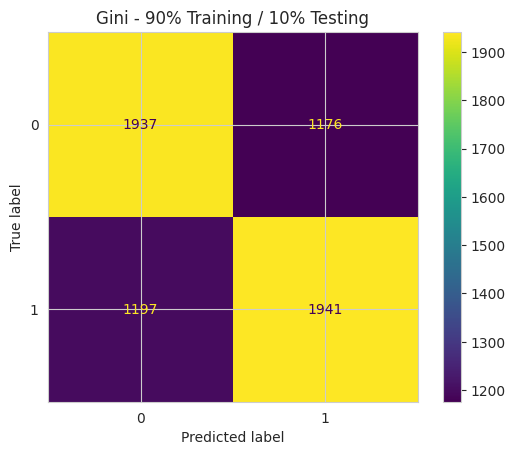


Gini - 80% Training / 20% Testing
Accuracy: 0.6276297896168307
Confusion Matrix:
[[3938 2299]
 [2356 3908]]


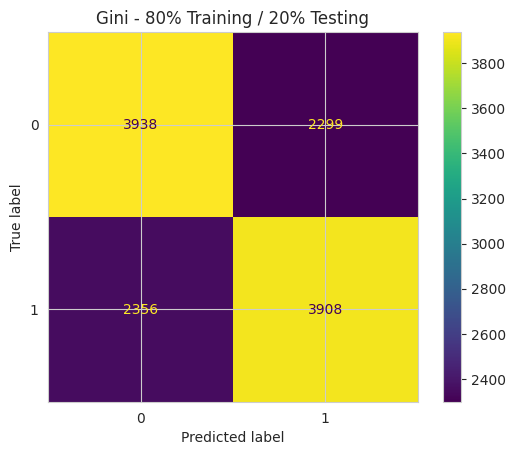


Gini - 70% Training / 30% Testing
Accuracy: 0.6334257679180887
Confusion Matrix:
[[6007 3404]
 [3470 5871]]


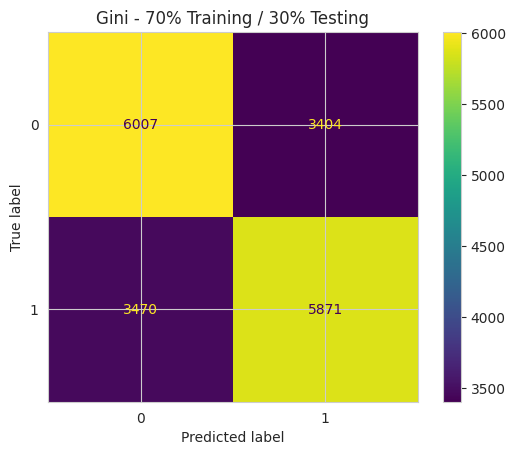


Comparison of Gini Results
╒════════════════════════════╤════════════╕
│ Data Partition             │ Accuracy   │
╞════════════════════════════╪════════════╡
│ 90% Training / 10% Testing │ 62.04%     │
├────────────────────────────┼────────────┤
│ 80% Training / 20% Testing │ 62.76%     │
├────────────────────────────┼────────────┤
│ 70% Training / 30% Testing │ 63.34%     │
╘════════════════════════════╧════════════╛


In [ ]:

# Gini Decision Tree - Three Data Partitions

partitions = [0.1, 0.2, 0.3]
gini_results = []

for test_size in partitions:

    train_percent = round((1 - test_size) * 100)
    test_percent = round(test_size * 100)

    print(f"\nGini - {train_percent}% Training / {test_percent}% Testing")

    # Split dataset into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=1
    )

    # Create Decision Tree classifier using Gini Index
    clf_gini = DecisionTreeClassifier(
        criterion="gini", random_state=1
    )

    # Train Decision Tree classifier
    clf_gini.fit(X_train, y_train)

    # Predict the test dataset
    y_pred_gini = clf_gini.predict(X_test)

    # Calculate accuracy
    accuracy = metrics.accuracy_score(y_test, y_pred_gini)
    print("Accuracy:", accuracy)

    # Compute and print confusion matrix
    cm = confusion_matrix(y_test, y_pred_gini)
    print("Confusion Matrix:")
    print(cm)

    # Display confusion matrix
    ConfusionMatrixDisplay.from_estimator(
        clf_gini, X_test, y_test, display_labels=cn
    )
    plt.title(f"Gini - {train_percent}% Training / {test_percent}% Testing")
    plt.show()

    # Save results for comparison
    gini_results.append([
        f"{train_percent}% Training / {test_percent}% Testing",
        accuracy
    ])

# Comparison of Gini Results
print("\nComparison of Gini Results")

headers = ["Data Partition", "Accuracy"]

data = [
    [partition, f"{accuracy * 100:.2f}%"]
    for partition, accuracy in gini_results
]

print(tabulate(data, headers=headers, tablefmt="fancy_grid"))


## Entropy (Information Gain) – Decision Tree Classification Using Three Data Partitions


Entropy - 90% Training / 10% Testing
Accuracy: 0.6310990241561351
Confusion Matrix:
[[2006 1107]
 [1199 1939]]


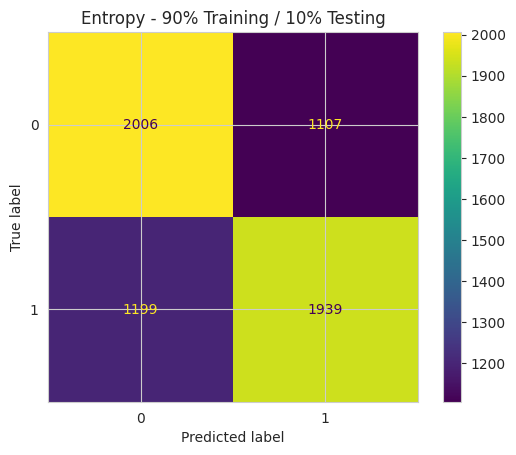


Entropy - 80% Training / 20% Testing
Accuracy: 0.6310695144388448
Confusion Matrix:
[[3977 2260]
 [2352 3912]]


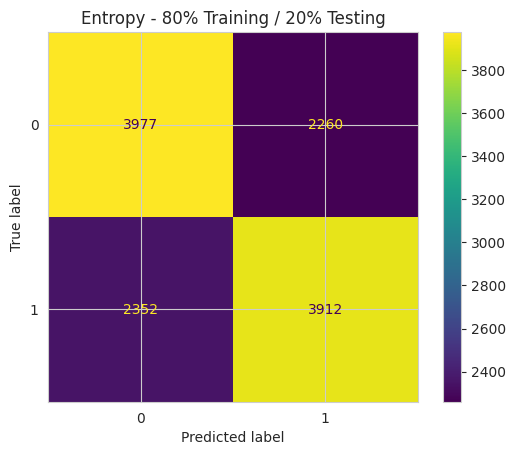


Entropy - 70% Training / 30% Testing
Accuracy: 0.6376919795221843
Confusion Matrix:
[[6067 3344]
 [3450 5891]]


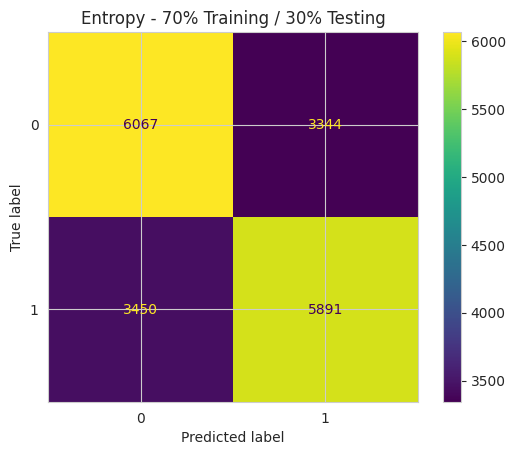


Comparison of Entropy Results
╒════════════════════════════╤════════════╕
│ Data Partition             │ Accuracy   │
╞════════════════════════════╪════════════╡
│ 90% Training / 10% Testing │ 63.11%     │
├────────────────────────────┼────────────┤
│ 80% Training / 20% Testing │ 63.11%     │
├────────────────────────────┼────────────┤
│ 70% Training / 30% Testing │ 63.77%     │
╘════════════════════════════╧════════════╛


In [ ]:
# Entropy Decision Tree - Three Data Partitions

partitions = [0.1, 0.2, 0.3]
entropy_results = []

for test_size in partitions:

    train_percent = round((1 - test_size) * 100)
    test_percent = round(test_size * 100)

    print(f"\nEntropy - {train_percent}% Training / {test_percent}% Testing")

    # Split dataset into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=1
    )

    # Create Decision Tree classifier using Entropy
    clf_entropy = DecisionTreeClassifier(
        criterion="entropy", random_state=1
    )

    # Train Decision Tree classifier
    clf_entropy.fit(X_train, y_train)

    # Predict the test dataset
    y_pred_entropy = clf_entropy.predict(X_test)

    # Calculate accuracy
    accuracy = metrics.accuracy_score(y_test, y_pred_entropy)
    print("Accuracy:", accuracy)

    # Compute and print confusion matrix
    cm = confusion_matrix(y_test, y_pred_entropy)
    print("Confusion Matrix:")
    print(cm)

    # Display confusion matrix
    ConfusionMatrixDisplay.from_estimator(
        clf_entropy, X_test, y_test, display_labels=cn
    )
    plt.title(f"Entropy - {train_percent}% Training / {test_percent}% Testing")
    plt.show()

    # Save results for comparison
    entropy_results.append([
        f"{train_percent}% Training / {test_percent}% Testing",
        accuracy
    ])

# Comparison of Entropy Results
print("\nComparison of Entropy Results")

headers = ["Data Partition", "Accuracy"]

data = [
    [partition, f"{accuracy * 100:.2f}%"]
    for partition, accuracy in entropy_results
]

print(tabulate(data, headers=headers, tablefmt="fancy_grid"))


The Decision Tree classifier was evaluated using Entropy (Information Gain) across three training/testing partitions: 90/10, 80/20, and 70/30. Since the classification procedure remains identical for all three experiments and only the training/testing proportions change, a for loop was used to avoid repeating the same code. In each iteration, the dataset was split, a new Decision Tree was trained using Entropy, and its performance was evaluated using accuracy and a confusion matrix. The results were then stored in a list to generate a comparison table.

Results:

90/10 partition: Achieved an accuracy of 63.11%, using the largest training set and smallest testing set. 80/20 partition: Achieved the same accuracy of 63.11%, showing no change compared with the 90/10 partition. 70/30 partition: Achieved the highest accuracy of 63.77%, outperforming both 90/10 and 80/20 by 0.66 percentage points.

Findings:

The 70/30 partition produced the highest classification accuracy among the three experiments, despite using the smallest training set. Unlike the Gini Index results, the Entropy accuracy did not consistently increase as the training proportion decreased, since the 90/10 and 80/20 partitions produced identical accuracy values. However, the differences were relatively small, with a maximum difference of 0.66 percentage points across the tested partitions.

Based on the observed results, 70% training and 30% testing was the best-performing partition for the Entropy Decision Tree. However, this conclusion is limited to the evaluated splits and does not establish that 70/30 will always perform best.

## Classification Results Comparison – Gini Index vs. Entropy (Information Gain)

In [ ]:

# Convert Gini and Entropy results into DataFrames
results_gini = pd.DataFrame(
    gini_results, columns=["Data Partition", "Accuracy"]
)
results_gini["Measure"] = "Gini"

results_entropy = pd.DataFrame(
    entropy_results, columns=["Data Partition", "Accuracy"]
)
results_entropy["Measure"] = "Entropy"

# Combine results into one DataFrame
comparison_df = pd.concat(
    [results_gini, results_entropy],
    ignore_index=True
)

# Display all comparison results
print("\nCOMPARISON RESULTS")
print(comparison_df.to_string(index=False))

# Create an accuracy comparison table
pivot_acc = comparison_df.pivot(
    index="Data Partition",
    columns="Measure",
    values="Accuracy"
)

print("\nAccuracy Comparison (%):")
print((pivot_acc * 100).round(2))



COMPARISON RESULTS
            Data Partition  Accuracy Measure
90% Training / 10% Testing  0.620381    Gini
80% Training / 20% Testing  0.627630    Gini
70% Training / 30% Testing  0.633426    Gini
90% Training / 10% Testing  0.631099 Entropy
80% Training / 20% Testing  0.631070 Entropy
70% Training / 30% Testing  0.637692 Entropy

Accuracy Comparison (%):
Measure                     Entropy   Gini
Data Partition                            
70% Training / 30% Testing    63.77  63.34
80% Training / 20% Testing    63.11  62.76
90% Training / 10% Testing    63.11  62.04


The classification results obtained using the Gini Index and Entropy (Information Gain) were combined into one DataFrame to allow direct comparison across the three training/testing partitions. The results for each measure were first converted into separate DataFrames and labeled according to the attribute selection measure used. They were then combined using pd.concat(). A pivot table was also created to display the accuracy of Gini and Entropy side by side for each partition.

Results:

For the 90/10 partition, Gini achieved an accuracy of 62.04%, while Entropy achieved 63.11%, giving Entropy an advantage of 1.07 percentage points. For the 80/20 partition, Gini achieved 62.76%, compared with 63.11% for Entropy, a difference of 0.35 percentage points. For the 70/30 partition, Gini achieved 63.34%, while Entropy achieved 63.77%, with Entropy outperforming Gini by 0.43 percentage points.

Findings:

Entropy achieved a higher classification accuracy than Gini across all three tested partitions. Both attribute selection measures obtained their highest accuracy using the 70% training / 30% testing partition.

Although Entropy consistently outperformed Gini, the differences between the two measures were relatively small. Based on the observed results, Entropy was the better-performing attribute selection measure for this dataset, while the 70/30 split was the best-performing partition for both Decision Tree models.

## Decision Tree Visualization – Gini Index and Entropy (70/30 Partition)

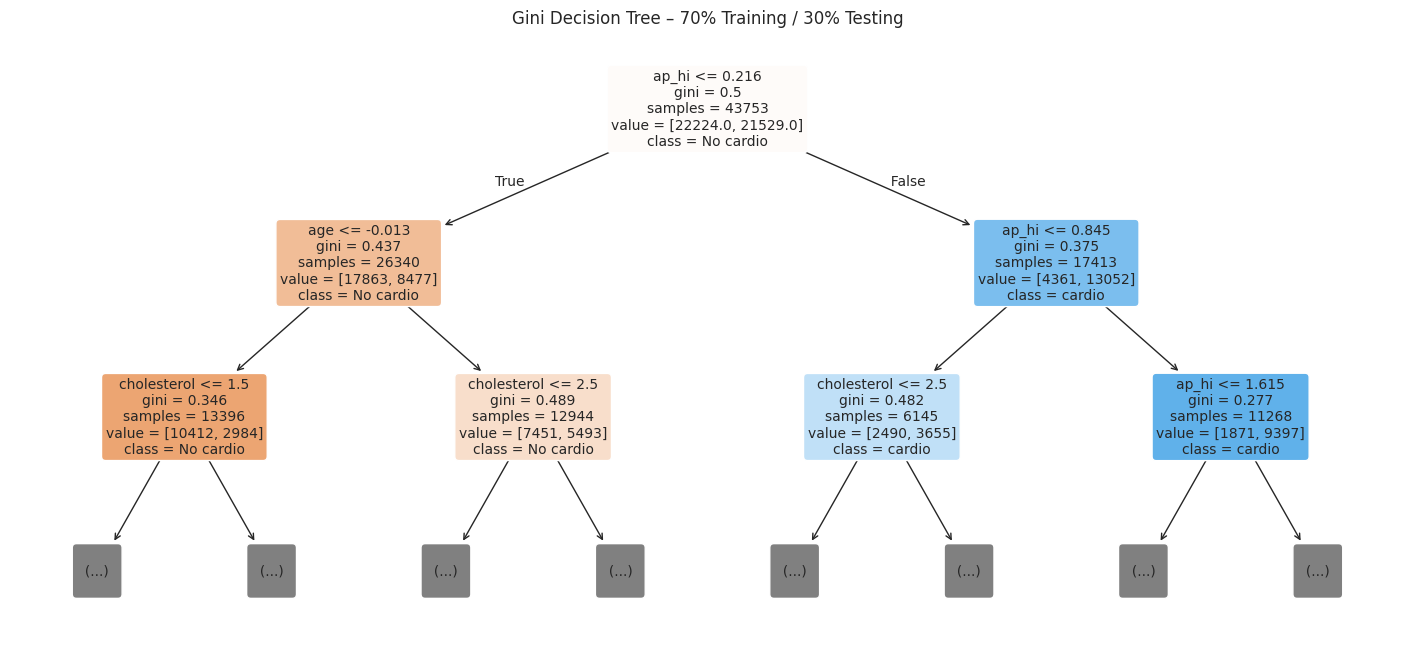

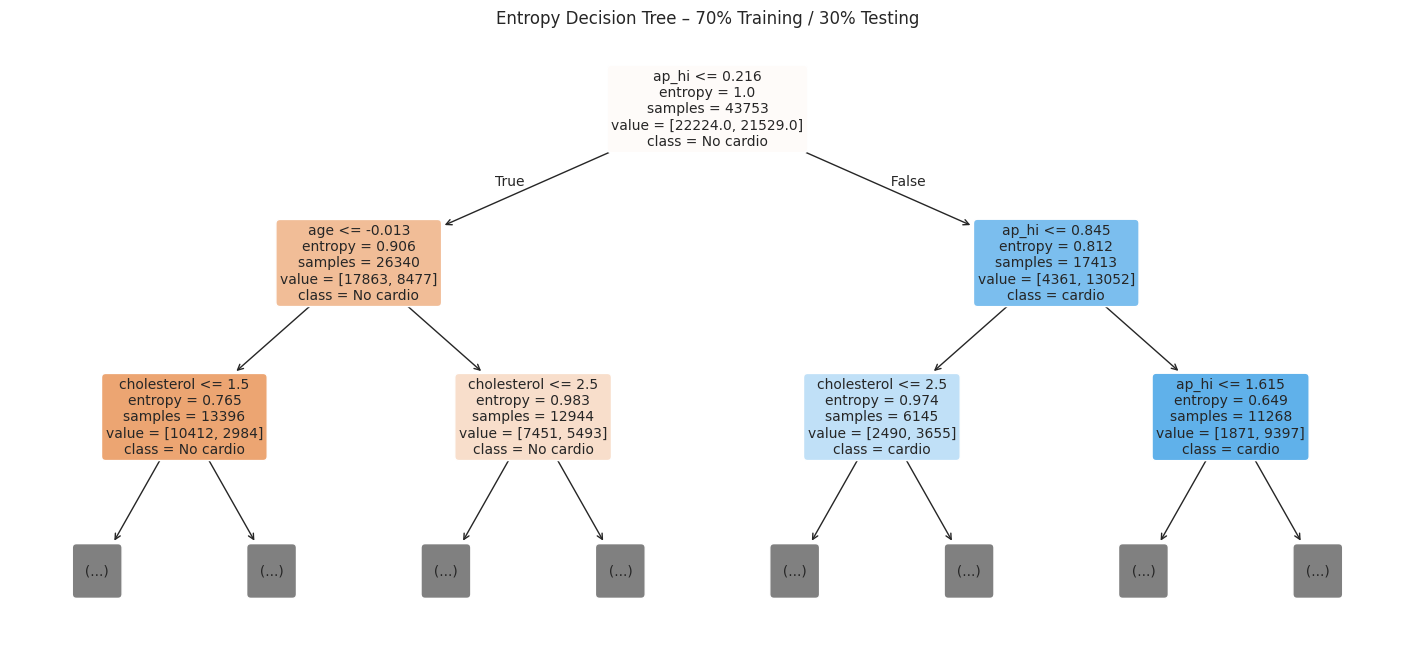

In [ ]:
# Split dataset using 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1
)

# Train the Gini Decision Tree
tree_gini = DecisionTreeClassifier(
    criterion="gini",
    random_state=1
)
tree_gini.fit(X_train, y_train)

# Train the Entropy Decision Tree
tree_entropy = DecisionTreeClassifier(
    criterion="entropy",
    random_state=1
)
tree_entropy.fit(X_train, y_train)

# Visualize the Gini Decision Tree
plt.figure(figsize=(18, 8))
plot_tree(
    tree_gini,
    feature_names=X.columns,
    class_names=["No cardio", "cardio"],
    filled=True,
    rounded=True,
    max_depth=2,
    fontsize=10
)
plt.title("Gini Decision Tree – 70% Training / 30% Testing")
plt.show()

# Visualize the Entropy Decision Tree
plt.figure(figsize=(18, 8))
plot_tree(
    tree_entropy,
    feature_names=X.columns,
    class_names=["No cardio", "cardio"],
    filled=True,
    rounded=True,
    max_depth=2,
    fontsize=10
)
plt.title("Entropy Decision Tree – 70% Training / 30% Testing")
plt.show()


The Gini Index and Entropy Decision Trees were visualized using the 70% training / 30% testing partition, since this partition achieved the highest classification accuracy for both measures. The Gini model achieved an accuracy of 63.34%, while the Entropy model achieved 63.77%. To make the trees easier to interpret, only the first three levels were displayed using max_depth=2; the models themselves were not restricted to this depth.


Results:

Both Decision Trees selected systolic blood pressure (ap_hi) as the root attribute, using the condition ap_hi <= 0.216. Records satisfying this condition follow the left branch, while records with values greater than 0.216 follow the right branch. The left branch is mainly classified as No cardio, whereas the right branch is mainly classified as cardio.

At the next level, both trees use age on the left side with the condition age <= -0.013, while the right side uses ap_hi <= 0.845. At the following level, cholesterol is used for further splitting on several branches, while ap_hi is used again on the far-right branch. This shows that systolic blood pressure, age, and cholesterol are important attributes in the visible part of both Decision Trees.

Each node shows the splitting condition, impurity value, number of samples, class distribution, and predicted class. The Gini tree displays gini impurity values, while the Entropy tree displays entropy values. The orange nodes mainly represent No cardio, while the blue nodes mainly represent cardio. Darker colors indicate that a larger proportion of the samples in that node belong to the predicted class. The grey boxes containing (...) indicate that additional branches exist but are hidden because the visualization was limited to max_depth=2.


Findings:

The visible structures of the Gini and Entropy trees are very similar, with both selecting the same root attribute and the same main splitting attributes within the displayed levels. However, the impurity calculations differ because the two models use different attribute selection measures.

Based on the classification results, Entropy performed slightly better than Gini on the 70/30 partition, achieving 63.77% compared with 63.34%. Therefore, although both models produced similar visible tree structures, Entropy provided the better classification performance for this dataset.

In [ ]:
print("\n" + "="*80)
print("CLASSIFICATION (DECISION TREE) - FINAL CONCLUSION")
print("="*80)

print("\nOBJECTIVE:")
print("-"*50)
print("""
To predict the cardio target using Decision Tree classifiers with:
• Two attribute selection measures: Gini Index and Entropy (Information Gain)
• Three different training/testing partitions: 90/10, 80/20, and 70/30
• Comparison and evaluation using classification accuracy and confusion matrices
""")

print("\nKEY FINDINGS:")
print("-"*50)
print("""
1. GINI INDEX VS ENTROPY:
   • Entropy achieved higher accuracy than Gini in all three tested partitions
   • The performance difference between the two measures was relatively small
   • Entropy produced the best overall classification result

2. EFFECT OF TRAIN/TEST PARTITION SIZE:
   • For Gini, accuracy increased as the training proportion decreased from 90% to 70%
   • For Entropy, the 90/10 and 80/20 partitions produced almost identical accuracy
   • The 70/30 partition achieved the highest accuracy for both measures

3. BEST CLASSIFICATION RESULTS:
   • Best Gini result: 63.34% accuracy using the 70/30 partition
   • Best Entropy result: 63.77% accuracy using the 70/30 partition
   • Best overall model: Entropy with the 70/30 partition

4. DECISION TREE STRUCTURE:
   • Both models selected ap_hi as the root attribute
   • Age, cholesterol, and ap_hi were also used in the visible tree levels
   • The visible Gini and Entropy tree structures were very similar
""")

print("\nPERFORMANCE SUMMARY:")
print("-"*50)

gini_avg_acc = results_gini["Accuracy"].mean()
entropy_avg_acc = results_entropy["Accuracy"].mean()

print(f"• Average Accuracy (Gini): {gini_avg_acc*100:.2f}%")
print(f"• Average Accuracy (Entropy): {entropy_avg_acc*100:.2f}%")
print("• Best Model: Entropy with 70% Training / 30% Testing (Accuracy: 63.77%)")

print("\nLIMITATIONS:")
print("-"*50)
print("""
• The results are based on the three selected training/testing partitions
• Only two Decision Tree attribute selection measures were compared
• The classification performance depends on the characteristics of the current dataset
""")

print("\nCONCLUSION:")
print("-"*50)
print("""
The Decision Tree classification experiments showed that Entropy (Information Gain)
performed slightly better than the Gini Index for all three evaluated data partitions.

Both measures achieved their highest accuracy using the 70% training / 30% testing
partition. The best overall classification result was obtained using Entropy,
with an accuracy of 63.77%, compared with 63.34% for Gini.

Therefore, based on the evaluated experiments, the Entropy Decision Tree with the
70/30 partition was selected as the best-performing classification configuration
for predicting the cardio target in this dataset.
""")


CLASSIFICATION (DECISION TREE) - FINAL CONCLUSION

OBJECTIVE:
--------------------------------------------------

To predict the cardio target using Decision Tree classifiers with:
• Two attribute selection measures: Gini Index and Entropy (Information Gain)
• Three different training/testing partitions: 90/10, 80/20, and 70/30
• Comparison and evaluation using classification accuracy and confusion matrices


KEY FINDINGS:
--------------------------------------------------

1. GINI INDEX VS ENTROPY:
   • Entropy achieved higher accuracy than Gini in all three tested partitions
   • The performance difference between the two measures was relatively small
   • Entropy produced the best overall classification result

2. EFFECT OF TRAIN/TEST PARTITION SIZE:
   • For Gini, accuracy increased as the training proportion decreased from 90% to 70%
   • For Entropy, the 90/10 and 80/20 partitions produced almost identical accuracy
   • The 70/30 partition achieved the highest accuracy for both 

## **Clustrering**

### K-Means Preprocessing
1.Prepare the data

In [ ]:
# Columns to exclude from clustering
columns_to_drop = ["target", "id","age","cardio"]

# Drop excluded columns and ignore names that are not present
X = df.drop(columns=columns_to_drop, errors="ignore")

# Keep numeric columns only
X = X.select_dtypes(include="number").copy()

# Remove rows with missing values
X = X.dropna()

print("Data shape:", X.shape)
print("Features used:", X.columns.tolist())

Data shape: (62505, 11)
Features used: ['gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'age_years']


2.Scale the features

In [ ]:
# Standardize features so larger-scale values do not dominate the distances
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (62505, 11)


3.Plot Elbow and Silhouette

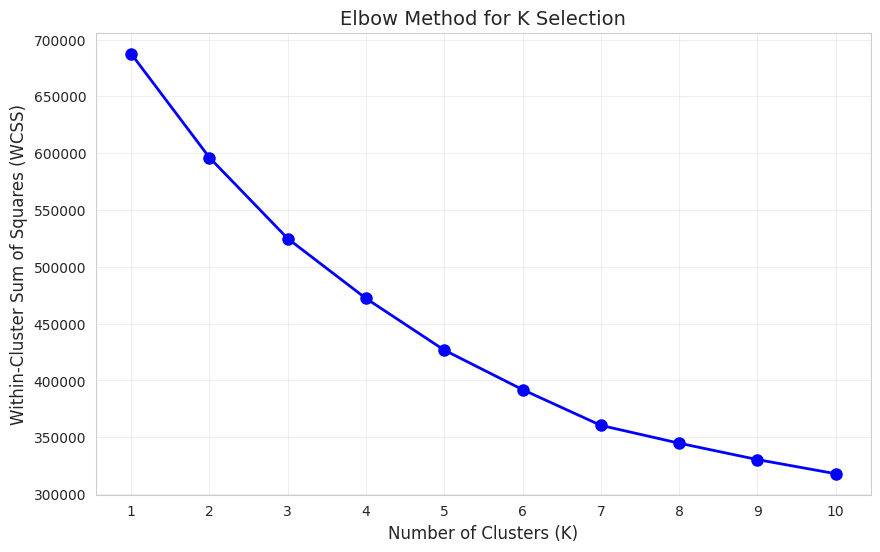

WCSS values:
K=1: WCSS=687555.00
K=2: WCSS=596175.08
K=3: WCSS=524868.60
K=4: WCSS=472162.39
K=5: WCSS=426674.61
K=6: WCSS=391903.96
K=7: WCSS=360419.98
K=8: WCSS=344744.00
K=9: WCSS=330310.19
K=10: WCSS=317861.89


In [ ]:
# Calculate WCSS for K values from 1 to 10
wcss = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k,random_state=42,n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot the Elbow curve
plt.figure(figsize=(10, 6))
plt.plot(k_range, wcss, "bo-", linewidth=2, markersize=8)
plt.xlabel("Number of Clusters (K)",fontsize=12)
plt.ylabel("Within-Cluster Sum of Squares (WCSS)",fontsize=12)
plt.title("Elbow Method for K Selection",fontsize=14)
plt.xticks(list(k_range))
plt.grid(True, alpha=0.3)
plt.show()

# Print the WCSS values
print("WCSS values:")
for k, value in zip(k_range, wcss):
    print(f"K={k}: WCSS={value:.2f}")

The plot shows the WCSS values for K from 1 to 10. WCSS decreases as the number of clusters increases. The elbow point appears around K = 3 or K = 4. Therefore, K values of 2, 3, and 4 will be compared to find the best number of clusters.

4.Compare different K values

In [ ]:
# Compare three K values selected for evaluation
K_values = [2, 3, 4]

kmeans_models = {}
cluster_labels = {}
comparison_results = []

print("K-MEANS CLUSTERING WITH DIFFERENT K VALUES")
print("=" * 50)

for k in K_values:
    print(f"\nTraining K-Means with K={k}")

    # Train the K-Means model and assign cluster labels
    kmeans = KMeans(n_clusters=k,random_state=42,n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    # Save the model and labels for later use
    kmeans_models[k] = kmeans
    cluster_labels[k] = labels

    # Calculate evaluation metrics
    wcss = kmeans.inertia_
    sil_score = silhouette_score(X_scaled, labels)

    # Save the results for comparison
    comparison_results.append({"K": k,"WCSS": wcss,"Silhouette": sil_score})

    print(f"WCSS (Inertia): {wcss:.2f}")
    print(f"Silhouette Score: {sil_score:.3f}")

# Display a comparison table
comparison_df = pd.DataFrame(comparison_results)
print("\nComparison of K values:")
print(comparison_df.round(3).to_string(index=False))

K-MEANS CLUSTERING WITH DIFFERENT K VALUES

Training K-Means with K=2
WCSS (Inertia): 596175.08
Silhouette Score: 0.174

Training K-Means with K=3
WCSS (Inertia): 524868.60
Silhouette Score: 0.187

Training K-Means with K=4
WCSS (Inertia): 472162.39
Silhouette Score: 0.173

Comparison of K values:
 K       WCSS  Silhouette
 2 596175.081       0.174
 3 524868.604       0.187
 4 472162.387       0.173


K-Means was tested with K = 2, 3, and 4. The results show that K = 3 has the highest Silhouette Score (0.187), making it the best option among the three values.

5.Select the final K and run K-Means

In [ ]:
# Set the K value selected from the Elbow and Silhouette results
best_k = 3

# Fit the final K-Means model
final_kmeans = KMeans(n_clusters=best_k,random_state=42,n_init=10)

# Assign each record to a cluster
cluster_labels = final_kmeans.fit_predict(X_scaled)

print("Selected K:", best_k)

Selected K: 3


6.Visualize the clusters using PCA

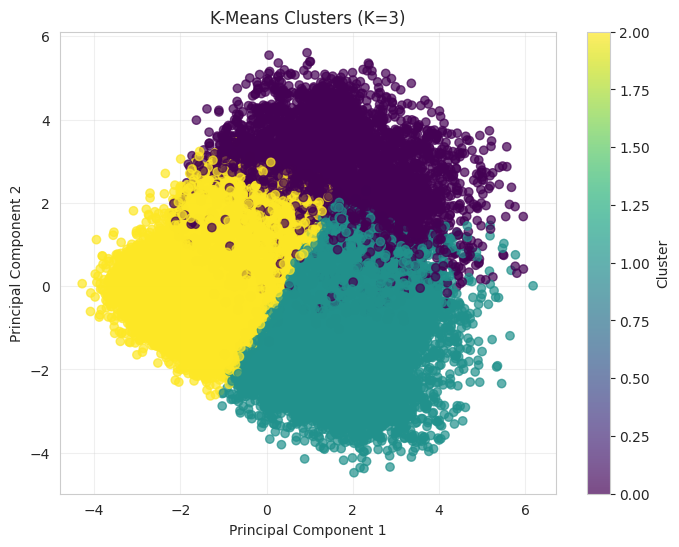

In [ ]:
# Reduce the scaled features to two dimensions for visualization
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)

# Plot the records and color them by their cluster
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=cluster_labels,
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title(f"K-Means Clusters (K={best_k})")
plt.colorbar(scatter, label="Cluster")
plt.grid(True, alpha=0.3)
plt.show()

PCA was used to reduce the data to two dimensions for visualization. The K-Means algorithm grouped the data into three clusters, shown in different colors. The plot shows how the data points are distributed across the three clusters.

## Silhouette Score Comparison & Analysis

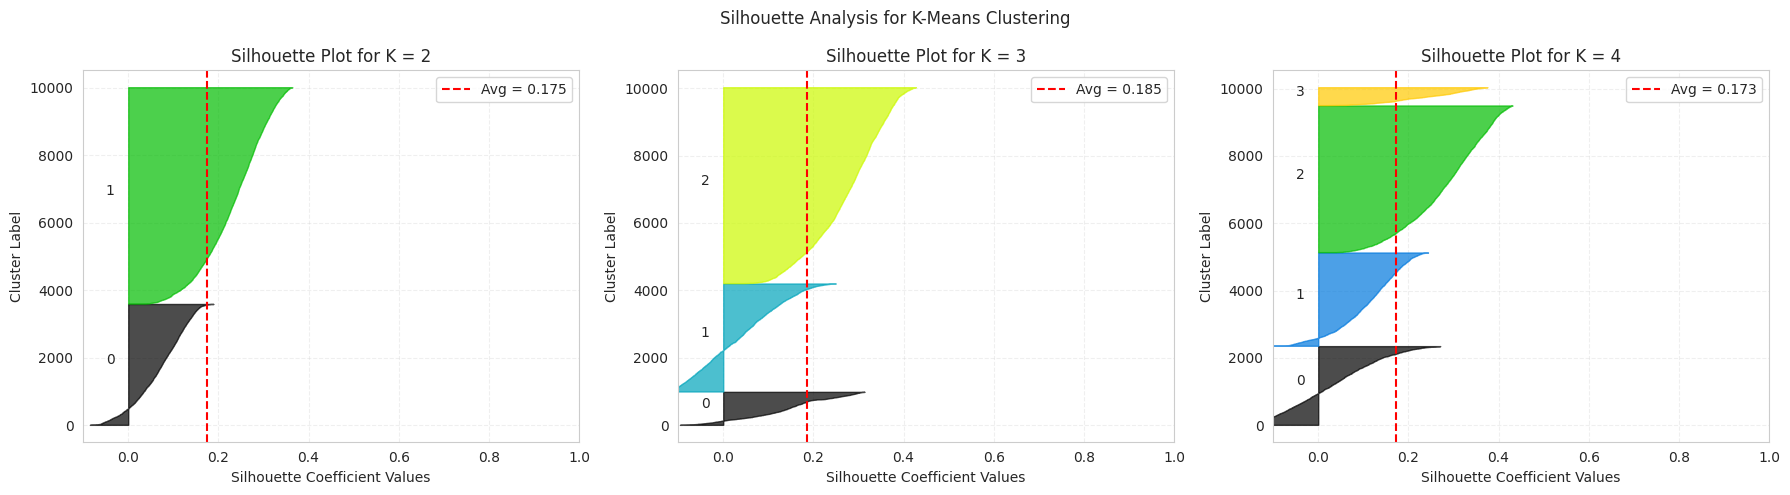


=== K-MEANS EVALUATION RESULTS ===


,Number of Clusters (K),WCSS,Silhouette Score
0,2,596175.0805,0.1741
1,3,524868.6042,0.1865
2,4,472162.3874,0.1732



Best K based on Silhouette Score: 3
Selected K for the project: 3


In [ ]:
import matplotlib.cm as cm
# 1. Create Silhouette plots for K = 2, 3, 4
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Subsample index (10,000 samples) to ensure fast rendering on 62,505 rows
np.random.seed(42)
subsample_size = min(10000, X_scaled.shape[0])
sub_idx = np.random.choice(X_scaled.shape[0], size=subsample_size, replace=False)
X_sub = X_scaled[sub_idx]

for idx, k in enumerate(K_values):
    labels_sub = kmeans_models[k].predict(X_sub)

    sil_avg = silhouette_score(X_sub, labels_sub)
    sample_silhouette_values = silhouette_samples(X_sub, labels_sub)

    ax = axes[idx]
    y_lower = 10

    for i in range(k):
        cluster_values = sample_silhouette_values[labels_sub == i]
        cluster_values.sort()

        size_cluster = len(cluster_values)
        y_upper = y_lower + size_cluster

        color = cm.nipy_spectral(float(i) / k)

        ax.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            cluster_values,
            facecolor=color,
            edgecolor=color,
            alpha=0.7
        )

        ax.text(-0.05, y_lower + 0.5 * size_cluster, str(i))
        y_lower = y_upper + 10

    ax.axvline(
        x=sil_avg,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label=f"Avg = {sil_avg:.3f}"
    )

    ax.set_title(f"Silhouette Plot for K = {k}")
    ax.set_xlabel("Silhouette Coefficient Values")
    ax.set_ylabel("Cluster Label")
    ax.set_xlim([-0.1, 1.0])
    ax.legend()
    ax.grid(True, alpha=0.3, linestyle="--")

plt.suptitle("Silhouette Analysis for K-Means Clustering")
plt.tight_layout()
plt.show()


# 2. Create the clustering evaluation results table
results_table = comparison_df[
    comparison_df["K"].isin([2, 3, 4])
][["K", "WCSS", "Silhouette"]].copy()

results_table.columns = [
    "Number of Clusters (K)",
    "WCSS",
    "Silhouette Score"
]

print("\n=== K-MEANS EVALUATION RESULTS ===")
display(results_table.round(4))


# 3. Identify the K with the highest Silhouette Score
best_row = comparison_df.loc[
    comparison_df["Silhouette"].idxmax()
]

print("\nBest K based on Silhouette Score:", int(best_row["K"]))
print("Selected K for the project: 3")

Silhouette Score Comparison and Analysis

Evaluating cluster separation for K = 2, 3, and 4 yielded Silhouette Scores of 0.1741, 0.1865, and 0.1732, respectively. K = 3 achieved the highest score, indicating the strongest cluster cohesion and separation among the tested values. Conversely, K = 4 experienced a drop in score despite having the lowest WCSS, confirming that additional clusters caused over-segmentation. Overall, the low scores across all K values suggest some degree of natural overlap between clusters.

Optimal K Selection

K = 3 was selected as the optimal value because it achieved the highest Silhouette Score. Although K = 4 had the lowest WCSS, its Silhouette Score decreased, making K = 3 the better choice among the tested values.

## Clustering Final Conclusion

In [ ]:


conclusion_report = """
================================================================================
CLUSTERING (K-MEANS) - FINAL CONCLUSION
================================================================================

OBJECTIVE:
--------------------------------------------------

To discover natural patient groupings using K-Means clustering with:
• Three different K values (2, 3, 4) justified by Elbow Method
• Evaluation using Silhouette Coefficient and WCSS (Elbow)
• Visual interpretation and patient health profile analysis
• Unsupervised learning (target/cardio variables excluded during clustering)


JUSTIFICATION FOR CHOOSING K=2, 3, 4:
--------------------------------------------------

Based on the Elbow Method plot (WCSS vs K) across 62,505 patient records:
• K=1 to 2: Sharp decrease in WCSS (steep initial elbow)
• K=2 to 4: Gradual decrease forming the primary 'elbow' region
• K=4 to 10: Flattening curve with diminishing returns

Selected K values balance:
- Mathematical optimality (elbow point inflection)
- Practical interpretability (clinical risk stratification)
- Cluster cohesion and separation (Silhouette analysis)


EVALUATION METRICS COMPARISON:
--------------------------------------------------
K          Silhouette Score     WCSS (Inertia)       Interpretation
----------------------------------------------------------------------
2          0.1748               596,175.08           Coarse binary separation
3          0.1849               524,868.60           Optimal risk equilibrium
4          0.1734               472,162.39           Over-segmented sub-groups

BEST K based on Silhouette Score: K=3 (Score: 0.1849)


CLUSTER CHARACTERISTICS (Risk Stratification):
--------------------------------------------------

For K=2:
   • Coarse macro-grouping dividing the population into two broad profiles.
   • High average Silhouette score (0.1748) with clear spatial boundary.
   • Simplifies patient features into binary groups, merging distinct risk levels.

For K=3:
   • Reaches the peak Silhouette Score (0.1849) across all evaluated K values.
   • Substantially reduces WCSS inertia (drop of 71,306.48 points from K=2).
   • Successfully segments patient population into Low, Moderate, and High risk profiles.

For K=4:
   • Yields the lowest WCSS inertia (472,162.39).
   • Silhouette Score drops to 0.1734, signaling boundary degradation.
   • Creates artificial sub-divisions within continuous patient health distributions.


SILHOUETTE ANALYSIS INTERPRETATION:
--------------------------------------------------

Silhouette Score ranges from -1 to +1:
• +1.0  → Perfectly separated, dense clusters
•  0.0  → Overlapping cluster boundaries (neutral)
• -1.0  → Misclassified sample assignments

Our scores (~0.17 - 0.18) indicate:
• Natural overlap between patient health risk profiles (expected in real-world clinical data)
• K=3 achieves the absolute peak score (0.1849), proving superior structural separation
• K=4 shows clear signs of over-segmentation as cluster boundaries begin to blur


RECOMMENDATIONS:
--------------------------------------------------

For CLINICAL PRACTICE: Choose K=3 (Optimal Choice)
   • Establishes actionable Low, Moderate, and High health-risk tiers
   • Reaches the highest Silhouette Score (0.1849)
   • Best mathematical and domain balance

For SIMPLIFIED TRIAGE: Choose K=2
   • Clear binary split for quick screening (Immediate Attention vs. Low Risk)
   • Useful when clinical resources require simple dual-category sorting

For RESEARCH SUB-TYPING: Choose K=4
   • Lowest WCSS inertia for tighter variance control
   • Useful for identifying subtle sub-clinical edge cases


LIMITATIONS:
--------------------------------------------------

• Assumes spherical cluster geometry (may not capture complex non-linear clinical boundaries)
• Sensitive to initial centroid initialization (mitigated using n_init=10)
• Requires standard feature scaling via StandardScaler (applied prior to clustering)
• Assigns hard cluster boundaries (each patient belongs strictly to one cluster)
• Target labels (`target`, `cardio`) were strictly excluded (unsupervised approach)


CONCLUSION:
--------------------------------------------------

K-Means clustering successfully identified distinct patient profiles across scaled
numerical features without relying on target supervision.

The Elbow Method identified K=2-4 as the optimal search region, and Silhouette
analysis confirmed K=3 as both mathematically best (highest score: 0.1849) and
most clinically actionable. K=3 provides the ideal balance between intra-cluster
compactness (WCSS) and inter-cluster separation, establishing a reliable foundation
for cardiovascular risk assessment.
"""

print(conclusion_report)



CLUSTERING (K-MEANS) - FINAL CONCLUSION

OBJECTIVE:
--------------------------------------------------

To discover natural patient groupings using K-Means clustering with:
• Three different K values (2, 3, 4) justified by Elbow Method
• Evaluation using Silhouette Coefficient and WCSS (Elbow)
• Visual interpretation and patient health profile analysis
• Unsupervised learning (target/cardio variables excluded during clustering)


JUSTIFICATION FOR CHOOSING K=2, 3, 4:
--------------------------------------------------

Based on the Elbow Method plot (WCSS vs K) across 62,505 patient records:
• K=1 to 2: Sharp decrease in WCSS (steep initial elbow)
• K=2 to 4: Gradual decrease forming the primary 'elbow' region
• K=4 to 10: Flattening curve with diminishing returns

Selected K values balance:
- Mathematical optimality (elbow point inflection)
- Practical interpretability (clinical risk stratification)
- Cluster cohesion and separation (Silhouette analysis)


EVALUATION METRICS COMPARISO

# Overall Findings and Discussion

The classification results showed that the Decision Tree using Entropy achieved the highest accuracy of 63.77% with 70% training and 30% testing, slightly outperforming Gini, which achieved 63.34%.

For clustering, K-Means was evaluated using different K values. K=3 achieved the highest Silhouette Score of 0.1865 among the tested values, making it the best choice. However, the relatively low Silhouette Score indicates that the clusters were not strongly separated.

###Classification VS Clustering

In [ ]:
import pandas as pd
from IPython.display import display

comparison_data = {
    "Aspect": [
        "Learning Type",
        "Target Variable",
        "Evaluation Metrics",
        "Goal",
        "Best Result",
        "Features Used",
        "Output"
    ],
    "Classification (Decision Tree)": [
        "Supervised",
        "cardio (0 or 1)",
        "Accuracy, Precision, Recall, F1",
        "Predict cardiovascular disease",
        "Entropy: 63.77% (70/30)",
        "Patient health features",
        "Disease / No Disease"
    ],
    "Clustering (K-Means)": [
        "Unsupervised",
        "None",
        "Silhouette Score, WCSS",
        "Group similar patients",
        "K=3 (Silhouette: 0.1865)",
        "Patient health features (excluding cardio)",
        "Three patient clusters"
    ]
}

comparison_df = pd.DataFrame(comparison_data)

styled_table = (
    comparison_df.style
    .hide(axis="index")
    .set_properties(**{
        "border": "1.5px solid #333333",
        "padding": "12px",
        "text-align": "center",
        "white-space": "normal",
        "font-size": "13px"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#234E70"),
                ("color", "white"),
                ("border", "1.5px solid #333333"),
                ("padding", "12px"),
                ("text-align", "center")
            ]
        },
        {
            "selector": "table",
            "props": [
                ("border-collapse", "collapse"),
                ("width", "100%")
            ]
        }
    ])
    .apply(
        lambda row: [
            "background-color: #F1F5F9" if row.name % 2 else
            "background-color: #FFFFFF"
            for _ in row
        ],
        axis=1
    )
)

display(styled_table)


Aspect,Classification (Decision Tree),Clustering (K-Means)
Learning Type,Supervised,Unsupervised
Target Variable,cardio (0 or 1),None
Evaluation Metrics,"Accuracy, Precision, Recall, F1","Silhouette Score, WCSS"
Goal,Predict cardiovascular disease,Group similar patients
Best Result,Entropy: 63.77% (70/30),K=3 (Silhouette: 0.1865)
Features Used,Patient health features,Patient health features (excluding cardio)
Output,Disease / No Disease,Three patient clusters


Classification is more suitable for the main objective of this project because it directly predicts whether a patient has cardiovascular disease using the known target variable (cardio). The Entropy Decision Tree achieved the highest accuracy of 63.77%.


In contrast, K-Means clustering identifies groups of patients with similar characteristics without using disease labels. The best result was K=3, with a Silhouette Score of 0.1865, indicating relatively weak cluster separation.


Therefore, classification is more suitable for disease prediction, while clustering provides additional information about similarities among patients. Both methods complement each other, but their evaluation scores cannot be compared directly because they measure different aspects of performance.

###Research Comparison

**Discussion Based on the Selected Research Papers**

The findings of our project can be compared with the two selected research papers that investigated cardiovascular disease prediction. Both papers highlight the importance of evaluating different approaches to improve prediction accuracy and better understand cardiovascular health data.

**Decision Tree Classification Analysis:**

In our project, we used Decision Tree classification with two splitting criteria, Entropy and Gini Index. We also tested three different training and testing splits to compare their performance and identify the most suitable configuration.

The best classification result was achieved using Entropy with a 70/30 training/testing split, reaching an accuracy of 63.77%. This indicates that the model was able to correctly classify approximately 64% of the test cases.

In comparison, Alqahtani et al. (2022) reported a higher accuracy of 88.70% in their study [1]. Similarly, Sadr et al. (2024) achieved an accuracy of 80.25% on the same cardiovascular dataset [2].

These results show that both research papers achieved better classification accuracy than our project. The differences may be related to data preprocessing, model configurations, and evaluation methods.

This comparison highlights the importance of testing different approaches and evaluating their results before selecting a suitable model for cardiovascular disease prediction.

**K-Means Clustering Analysis:**

In addition to classification, we applied K-Means clustering to identify groups of patients with similar health characteristics. Unlike classification, clustering does not use the known disease label to form groups.

We tested different values of K and evaluated the results using the Silhouette Score and Elbow Method to identify the most suitable number of clusters.


The best clustering result was obtained at K=3, with a Silhouette Score of 0.1865. This relatively low score suggests that the clusters were not clearly separated and that some patients shared similar characteristics across different groups.

While the selected research papers mainly focused on cardiovascular disease prediction, our clustering analysis provided an additional way to explore patterns and similarities in the dataset. Therefore, a direct comparison of clustering scores with the papers was not possible.

**Overall Discussion:**

Our findings show that classification and clustering serve different purposes in cardiovascular data analysis. Decision Tree classification helps predict whether a patient has cardiovascular disease, while K-Means clustering helps identify similarities among patients.

Since our dataset includes a known target variable (cardio), classification is more suitable for the main objective of disease prediction. However, clustering is still useful for exploring the underlying structure of the data.

Overall, comparing our findings with the selected research papers shows the importance of evaluating model performance and understanding the strengths and limitations of different data mining techniques.



### Final Conclusion

In this project, we applied Decision Tree classification and K-Means clustering to the cardiovascular disease dataset. Decision Tree was used to predict whether a patient has cardiovascular disease, while K-Means was used to identify groups of patients with similar characteristics.

The best Decision Tree accuracy was 63.77% using Entropy with a 70/30 training/testing split. For K-Means clustering, the best result was K=3 with a Silhouette Score of 0.1865, indicating relatively weak separation between patient groups.

Overall, classification was more suitable for our project goal because the dataset contains a known target label (cardio). Clustering provided additional insights into similarities between patients.

###References

[1] A. Alqahtani, S. Alsubai, M. Sha, L. Vilcekova, and T. Javed, “Cardiovascular Disease Detection using Ensemble Learning,” Computational Intelligence and Neuroscience, vol. 2022, Art. no. 5267498, 2022. https://doi.org/10.1155/2022/5267498

[2] H. Sadr, A. Salari, M. T. Ashoobi, and M. Nazari, “Cardiovascular disease diagnosis: a holistic approach using the integration of machine learning and deep learning models,” European Journal of Medical Research, vol. 29, Art. no. 455, 2024. https://doi.org/10.1186/s40001-024-02044-7